In [3]:
%load_ext pyspecdata.ipy
from itertools import cycle
import matplotlib.pyplot as plt
import numpy as np

The pyspecdata.ipy extension is already loaded. To reload it, use:
  %reload_ext pyspecdata.ipy


First, we load our files, and just see what the data looks like

In [4]:
d = find_file("240220_TempoSO4_W3_run3.DSC", exp_type="francklab_esr/romana") #heating 
d.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (7, 'Temperature'), (10, 'harmonic')]

In [5]:
d.chunk_auto(
    "harmonic", "harmonic"
)  # the harmonic is typically stored so that we need to do this
d.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (7, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

I start by plotting as a 2D pcolor plot:

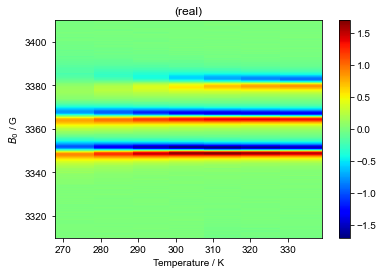

In [6]:
d = d["harmonic", 0][
    "phase", 0
]  # select only the "standard" EPR -- ignore the higher harmonics.  Make sure you can parse this!
d.pcolor()

From this, I learn that
it's easiest to show the 1D plots above and below the transition

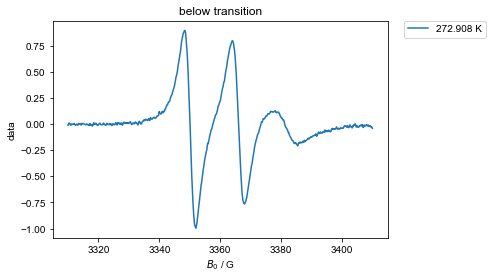

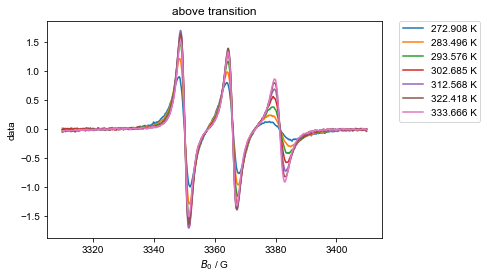

In [7]:
for this_label, temp_range in [
    ("below transition", (None, 247.8)),
    ("above transition", (248, None)),
]:
    this_d = d["Temperature":temp_range]
    figure() # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d.shape["Temperature"]):
        this_temp = this_d.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d["Temperature", temp_ithis_dx], label=f"{this_temp} K")
    fancy_legend()

What if I wanted to pull the max and min to calculate the correlation time? How would I do that?

Start by slicing out the left peak -- note that the way I loaded pyspecdata at the top, inspecting an nddata just gives me a plot:

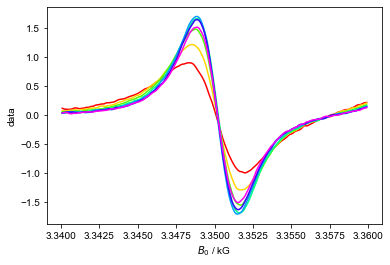

In [6]:
d["Temperature":(258,None)]['$B_0$':(3340,3360)]

Here, I'm going to take the peak I just sliced, and determine its linewidth.  This is a simple example, but contains all the programming that I would need to, e.g. determine the correlation time or the hyperfine coupling using the traditional methods that look at the peak heights and linewidths:

the linewidth at 272.908 K is 3.6132812590417416 G
the peak to peak amplitude at 272.908 K is 1.8921827092913879
the linewidth at 283.496 K is 3.12500000782029 G
the peak to peak amplitude at 283.496 K is 2.4957688074832776
the linewidth at 293.576 K is 2.929687507331437 G
the peak to peak amplitude at 293.576 K is 3.027743031023551
the linewidth at 302.685 K is 2.7343750068425834 G
the peak to peak amplitude at 302.685 K is 3.339068824031494
the linewidth at 312.568 K is 2.6367187565979293 G
the peak to peak amplitude at 312.568 K is 3.395475124982581
the linewidth at 322.418 K is 2.6367187565979293 G
the peak to peak amplitude at 322.418 K is 3.2652666631828313
the linewidth at 333.666 K is 2.6367187565979293 G
the peak to peak amplitude at 333.666 K is 3.012817248902592


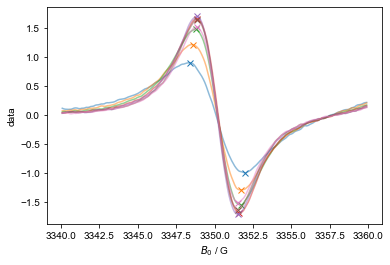

In [7]:
this_d = d["Temperature":(258,None)]['$B_0$':(3340,3360)]
default_color_cycle = cycle(rcParams['axes.prop_cycle'].by_key()['color'])
for j in range(this_d.shape["Temperature"]):
    c = next(default_color_cycle)
    plot(this_d['Temperature',j],alpha=0.5,c=c)
    field_at_max = this_d['Temperature',j].argmax().item()
    plot(field_at_max,this_d['Temperature',j]['$B_0$':field_at_max].item(),'x',c=c)
    field_at_min = this_d['Temperature',j].argmin()['$B_0$'] # it's a pyspecdata error that this isn't the same as argmax
    plot(field_at_min,this_d['Temperature',j]['$B_0$':field_at_min].item(),'x',c=c)
    print("the linewidth at",this_d['Temperature'][j],"K is",field_at_min-field_at_max,"G")
    print("the peak to peak amplitude at",this_d['Temperature'][j],"K is",(
        this_d['Temperature',j]['$B_0$':field_at_max].item()
        - this_d['Temperature',j]['$B_0$':field_at_min].item()))